# Student Exam Performance Predictor

**Assignment 1 — Individual Project**  
**Hind Alhmoudi**

A reproducible prototype for the Academic Support Office using the exact 13 supplied study-hours and exam-score observations. The report follows the seven required stages, from project planning to a final recommendation.

**How to run:** Select a Python environment with the packages in `requirements.txt`, then restart the kernel and run all cells in order. The dataset is embedded below; no external data file or network access is needed. All scores are expressed in points because the assignment does not specify the marking scale or the period over which study hours were measured.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from IPython.display import display
from IPython.display import Markdown

# Consistent, readable plot styling.
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

Matplotlib is building the font cache; this may take a moment.


## 1. Project Definition and SDLC Plan

### A. Requirements
The Academic Support Office needs a small prototype to explore whether study hours are associated with exam performance. The prediction input is a student's study hours, while the supplied study-hour and exam-score pairs provide the data used to develop the model. The main outputs are summary statistics, visualizations, a fitted Linear Regression model, and MAE on held-out observations. The prototype should estimate a score for a given number of study hours, including 7.5 hours, and explain when that estimate should not be trusted.

### B. SDLC plan

| SDLC stage | Application to this project |
| --- | --- |
| Requirements | Use the supplied data to describe the study-hours/score relationship, estimate scores, and explain accuracy and limitations to academic support staff. |
| Design | Store the data in NumPy arrays, organize it in a Pandas table, inspect it, plot it, split it into training and test sets, fit a model, and interpret its predictions. |
| Implementation | Use NumPy for statistics, Pandas for inspection and filtering, Matplotlib for plots, and scikit-learn for the split, Linear Regression, predictions, and MAE. |
| Testing | Check array lengths and statistical consistency, keep test rows out of fitting, calculate test MAE, and use Restart Kernel & Run All to check the complete notebook. |
| Improvement | Collect more representative student records with attendance, prior grades, assignment scores, sleep, and course difficulty; compare models with cross-validation. |

### C. Project flow
Problem Definition → Data Setup (NumPy) → Data Inspection (Pandas) → Visualization (Matplotlib) → Model Training (scikit-learn) → Prediction → Evaluation (MAE) → Conclusion

## 2. Numerical Data Setup and Basic Statistics — NumPy

### A. Create the arrays
Each position in the two arrays represents the same student observation. I keep the supplied values in their original order.

In [2]:
study_hours = np.array([1.0, 2.0, 2.5, 3.0, 4.0, 4.5, 5.0, 6.0, 6.5, 7.0, 8.0, 9.0, 10.0])
exam_scores = np.array([42, 48, 51, 55, 62, 65, 69, 75, 78, 82, 87, 91, 95])

print(f"Study-hours array: {study_hours}")
print(f"Exam-score array: {exam_scores}")
print(f"Study-hours count: {len(study_hours)}; shape: {study_hours.shape}")
print(f"Exam-score count: {len(exam_scores)}; shape: {exam_scores.shape}")
print(f"Array shapes match: {study_hours.shape == exam_scores.shape}")
assert study_hours.shape == exam_scores.shape == (13,)
assert np.isfinite(study_hours).all() and np.isfinite(exam_scores).all()

Study-hours array: [ 1.   2.   2.5  3.   4.   4.5  5.   6.   6.5  7.   8.   9.  10. ]
Exam-score array: [42 48 51 55 62 65 69 75 78 82 87 91 95]
Study-hours count: 13; shape: (13,)
Exam-score count: 13; shape: (13,)
Array shapes match: True


Both arrays contain 13 observations and have matching shapes, so every study-hours value has a corresponding exam score. The arrays contain no missing or infinite numerical values.

### B. Numerical profile
I calculate the summaries directly from the arrays. `np.std()` uses the population standard deviation (`ddof=0`) by default, which describes the spread of this supplied set of observations.

In [3]:
observation_count = len(exam_scores)
mean_hours = np.mean(study_hours)
mean_score = np.mean(exam_scores)
minimum_score = np.min(exam_scores)
maximum_score = np.max(exam_scores)
population_std = np.std(exam_scores)

print(f"Number of observations: {observation_count}")
print(f"Mean study hours: {mean_hours:.4f} hours")
print(f"Mean exam score: {mean_score:.4f} points")
print(f"Minimum exam score: {minimum_score} points")
print(f"Maximum exam score: {maximum_score} points")
print(f"Population standard deviation of scores (ddof=0): {population_std:.4f} points")

Number of observations: 13
Mean study hours: 5.2692 hours
Mean exam score: 69.2308 points
Minimum exam score: 42 points
Maximum exam score: 95 points
Population standard deviation of scores (ddof=0): 16.4651 points


Students in this dataset studied an average of 5.27 hours and scored an average of 69.23 points. Scores range from 42 to 95, with a population standard deviation of 16.47 points, so there is a noticeable spread in performance.

### C and D. Above-average performers
I compare all scores with the same mean in one vectorized operation, then sum the resulting Boolean array.

In [4]:
above_mean_mask = exam_scores > np.mean(exam_scores)
above_mean_count = np.sum(above_mean_mask)

print(f"Above-mean Boolean mask: {above_mean_mask}")
print(f"Students scoring strictly above the mean: {above_mean_count}")

Above-mean Boolean mask: [False False False False False False False  True  True  True  True  True
  True]
Students scoring strictly above the mean: 6


`exam_scores > np.mean(exam_scores)` produces one `True` or `False` per student by comparing each score with the mean of 69.23 points. Summing the array counts the `True` values because `True` contributes 1 and `False` contributes 0; here, 6 students score strictly above the mean.

Overall, the 13 observations cover a broad score range, while the average student in this dataset studied about 5.27 hours. These summaries describe the sample, but the table and plot are needed to examine how the two variables relate.

## 3. Structured Dataset and Data Inspection — Pandas

### A and B. Build and inspect the table
The DataFrame below uses the same NumPy arrays. `df.head()` gives a quick check of the column names and the first few paired observations.

In [5]:
df = pd.DataFrame({"StudyHours": study_hours, "ExamScore": exam_scores})
print(f"First {len(df.head())} observations — df.head():")
display(df.head())
assert not df.isna().any().any()
assert np.array_equal(df["StudyHours"].to_numpy(), study_hours)
assert np.array_equal(df["ExamScore"].to_numpy(), exam_scores)
print("Data checks passed: paired values preserved; no missing values.")

First 5 observations — df.head():


,StudyHours,ExamScore
0,1.0,42
1,2.0,48
2,2.5,51
3,3.0,55
4,4.0,62


Data checks passed: paired values preserved; no missing values.


The preview shows the first 5 supplied observations with clear column labels. The row alignment preserves each student's study hours and score.

In [6]:
print(f"DataFrame shape — df.shape: {df.shape}")
print(f"Rows: {df.shape[0]}; columns before adding AboveAverage: {df.shape[1]}")

DataFrame shape — df.shape: (13, 2)
Rows: 13; columns before adding AboveAverage: 2


The table has 13 rows and 2 columns at this stage: one observation per row, with study hours and exam score stored separately.

In [7]:
summary = df.describe()
print("Numerical summary — df.describe():")
display(summary)

Numerical summary — df.describe():


,StudyHours,ExamScore
count,13.000000,13.000000
mean,5.269231,69.230769
std,2.781002,17.137453
min,1.000000,42.000000
25%,3.000000,55.000000
50%,5.000000,69.000000
75%,7.000000,82.000000
max,10.000000,95.000000


`df.describe()` reports the count, mean, standard deviation, minimum, quartiles, and maximum for each numeric column. Its mean score of 69.23, minimum of 42, and maximum of 95 agree with NumPy, but its score standard deviation is 17.14 rather than 16.47 because Pandas uses the sample formula (`ddof=1`).

In [8]:
sample_std = np.std(exam_scores, ddof=1)
print(f"NumPy sample score standard deviation (ddof=1): {sample_std:.4f} points")
print(f"Pandas score standard deviation: {summary.loc['std', 'ExamScore']:.4f} points")
print(f"Sample standard deviations agree: {np.isclose(sample_std, summary.loc['std', 'ExamScore'])}")

assert np.isclose(summary.loc["mean", "StudyHours"], mean_hours)
assert np.isclose(summary.loc["mean", "ExamScore"], mean_score)
assert np.isclose(summary.loc["std", "ExamScore"], sample_std)
assert summary.loc["min", "ExamScore"] == minimum_score
assert summary.loc["max", "ExamScore"] == maximum_score

NumPy sample score standard deviation (ddof=1): 17.1375 points
Pandas score standard deviation: 17.1375 points
Sample standard deviations agree: True


Setting NumPy's `ddof` to 1 gives 17.1375 points, matching Pandas. The earlier difference comes from the denominator used in the formula, not from a mismatch in the data.

### C. Add the reporting feature
`AboveAverage` is calculated from the scores, so I use it only for reporting and never as a prediction input.

In [9]:
df["AboveAverage"] = df["ExamScore"] > df["ExamScore"].mean()
print("Complete dataset with AboveAverage:")
display(df)
print(f"AboveAverage count in Pandas: {df['AboveAverage'].sum()}")
print(f"Count matches NumPy: {df['AboveAverage'].sum() == above_mean_count}")
assert np.array_equal(df["AboveAverage"].to_numpy(), above_mean_mask)

Complete dataset with AboveAverage:


,StudyHours,ExamScore,AboveAverage
0,1.0,42,False
1,2.0,48,False
2,2.5,51,False
3,3.0,55,False
4,4.0,62,False
5,4.5,65,False
6,5.0,69,False
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True


AboveAverage count in Pandas: 6
Count matches NumPy: True


Pandas marks the same 6 students as above average, confirming agreement with Stage 2. Since this column depends on the score we want to predict, including it in the model would reveal information about the target.

### D. Answer the stakeholder query
The Academic Support Office wants observations where students studied at least 6 hours and scored at least 75 points. Both conditions must hold, so I combine the parenthesized comparisons with `&`.

In [10]:
matching_students = df[(df["StudyHours"] >= 6) & (df["ExamScore"] >= 75)]
print("Students with at least 6 study hours and at least 75 score points:")
display(matching_students)
print(f"Number of matching students: {len(matching_students)}")

Students with at least 6 study hours and at least 75 score points:


,StudyHours,ExamScore,AboveAverage
7,6.0,75,True
8,6.5,78,True
9,7.0,82,True
10,8.0,87,True
11,9.0,91,True
12,10.0,95,True


Number of matching students: 6


The filter returns 6 observations, including the student at exactly 6 hours and 75 points. The `>=` comparisons include students on either boundary.

### E. Why Pandas suits this stage
NumPy is convenient for numerical calculations on arrays. Pandas adds labeled columns, allows numeric and Boolean data in the same table, and provides `describe()`, readable filters, and easy derived columns. This makes it simpler to show the Academic Support Office exactly which observations meet its criteria.

## 4. Exploratory Visualization — Matplotlib

### A. Plot the raw observations
I inspect the scatter plot before creating a model. The plotting function keeps the labels and styling consistent when I add the fitted line later.

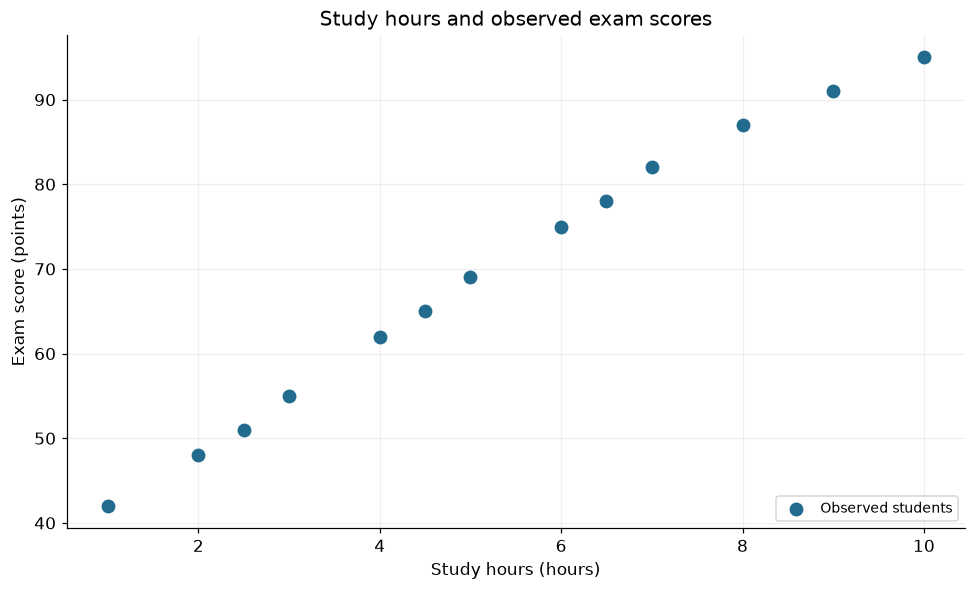

In [11]:
def plot_student_scores(fitted_model=None):
    """Draw raw observations, then optionally show the training-only model."""
    fig, ax = plt.subplots(figsize=(9, 5.5))
    if fitted_model is None:
        ax.scatter(df["StudyHours"], df["ExamScore"], s=65, color="#236B8E",
                   label="Observed students", zorder=3)
        ax.set_title("Study hours and observed exam scores")
    else:
        # All line coordinates come from the trained model's predictions.
        line_hours = pd.DataFrame({
            "StudyHours": np.linspace(study_hours.min(), study_hours.max(), 100)
        })
        ax.axvspan(study_hours.min(), X_train["StudyHours"].min(),
                   color="#EDF0F3", label="Below training input range")
        ax.plot(line_hours["StudyHours"], fitted_model.predict(line_hours),
                color="#243746", linewidth=2, label="Training-set regression line")
        ax.scatter(X_train["StudyHours"], y_train, s=65, color="#236B8E",
                   label=f"Training observations (n={len(y_train)})", zorder=3)
        ax.scatter(X_test["StudyHours"], y_test, s=80, color="#C65D21", marker="s",
                   label=f"Held-out observations (n={len(y_test)})", zorder=4)
        ax.vlines(X_test["StudyHours"], y_test, fitted_model.predict(X_test),
                  color="#C65D21", linewidth=2, label="Held-out prediction gaps")
        ax.set_title("Linear Regression fitted only on training observations")
    ax.set_xlabel("Study hours (hours)")
    ax.set_ylabel("Exam score (points)")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right", fontsize=9)
    fig.tight_layout()
    plt.show()

plot_student_scores()

### B. Pre-model observation
The plot shows a strong positive association: higher study hours tend to go with higher exam scores, and the points lie close to a straight upward trend. There are no obvious isolated outliers, although the increase looks slightly flatter at the upper end. This pattern does not show that extra study hours alone cause higher scores.

**C and D:** The fitted overlay and its interpretation appear in Section 5F after training. This keeps the notebook executable from top to bottom.

## 5. Linear Regression Model — scikit-learn

### A. Prepare the input and target
Study hours are the only model feature. The double brackets keep `X` as a DataFrame with rows and columns, while the single brackets produce the target Series `y`.

In [12]:
X = df[["StudyHours"]]
y = df["ExamScore"]
print(f"X shape (observations, features): {X.shape}")
print(f"y shape (observations,): {y.shape}")
assert X.ndim == 2 and X.shape[1] == 1

X shape (observations, features): (13, 1)
y shape (observations,): (13,)


`X` has shape (13, 1), meaning 13 students and one feature; `y` has shape (13,). Scikit-learn expects `X` to be two-dimensional so it can distinguish observations from features even when only one feature is used.

### B. Reserve test observations
I use the required split settings exactly. Keeping the random seed fixed makes this particular split reproducible.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")
print(f"Training and test rows are separate: {set(X_train.index).isdisjoint(X_test.index)}")
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)
print(f"Training study-hour range: {X_train['StudyHours'].min():g}–{X_train['StudyHours'].max():g} hours")
print("Held-out study hours:", sorted(X_test["StudyHours"].tolist()))

Training observations: 10
Test observations: 3
Training and test rows are separate: True
Training study-hour range: 2–10 hours
Held-out study hours: [1.0, 7.0, 9.0]


The split gives 10 training observations and 3 test observations; the test count is rounded up for this small dataset. The model will learn from the training rows, while the held-out rows will be used to check predictions.

Training inputs span 2–10 hours, while the full dataset spans 1–10 hours. The held-out 1-hour observation is therefore a small extrapolation relative to the training range. This is different from the much more extreme 100-hour scenario considered later.

### C. Fit the model
Linear Regression estimates a straight-line relationship using only the training data.

In [14]:
model = LinearRegression()
model.fit(X_train, y_train)
coefficient = model.coef_[0]
intercept = model.intercept_
print(f"Coefficient: {coefficient:.6f} exam-score points per study hour")
print(f"Intercept: {intercept:.6f} exam-score points")
print(f"Fitted equation: predicted score = {intercept:.6f} + {coefficient:.6f} × study hours")

Coefficient: 6.071273 exam-score points per study hour
Intercept: 37.232942 exam-score points
Fitted equation: predicted score = 37.232942 + 6.071273 × study hours


Each additional study hour is associated with roughly 6.07 more predicted exam-score points in this fitted relationship. The intercept, 37.23, is the model's prediction at zero hours, which lies outside the observed range and should not be treated as a reliable real-student score.

### D. Predict the held-out scores
The error below is signed: actual score minus predicted score. It helps show which estimates are above or below the observed scores.

In [15]:
predictions = model.predict(X_test)
test_results = X_test.copy()
test_results["ActualScore"] = y_test
test_results["PredictedScore"] = predictions
test_results["Error"] = y_test.to_numpy() - predictions
test_results["AbsoluteError"] = np.abs(test_results["Error"])
print("Held-out results — Error = ActualScore − PredictedScore:")
display(test_results.sort_values("StudyHours").round(4))

Held-out results — Error = ActualScore − PredictedScore:


,StudyHours,ActualScore,PredictedScore,Error,AbsoluteError
0,1.0,42,43.3042,-1.3042,1.3042
9,7.0,82,79.7319,2.2681,2.2681
11,9.0,91,91.8744,-0.8744,0.8744


The table compares predictions with the actual scores for the 3 held-out students. A positive error means the model underestimated the score, while a negative error means it overestimated it; the small gaps here will be summarized with MAE in Stage 6. The AbsoluteError column removes the signs and provides the values that MAE averages.

### E. Explain the model pipeline

**What are X and y?** `X` contains study hours, the information available when estimating a student's score. `y` contains the observed exam scores that the model tries to learn to predict.

**Why hold out test data?** I need to check predictions on students whose scores were not used to fit the line. Evaluating only on training students could give the Academic Support Office an overly optimistic view of performance.

**What does model.fit() learn?** It receives the training study hours and scores, finds the slope and intercept that minimize the sum of squared training errors, and stores them in the fitted model. It returns that fitted model object.

**What does model.predict() return?** It receives a two-dimensional table of study hours and applies the learned equation to each row. It returns an array containing one estimated exam score per student.

**What does the coefficient mean?** Each additional study hour is associated with roughly 6.07 more predicted exam-score points in this dataset. The coefficient describes an association, and the intercept of 37.23 is a mathematical parameter rather than a validated score for a student who does not study.

### F. Completion of Stage 4: fitted regression line
The line below comes from `model.predict()` across the observed range. The same plotting function redraws the observations and overlays the model fitted in Stage 5.

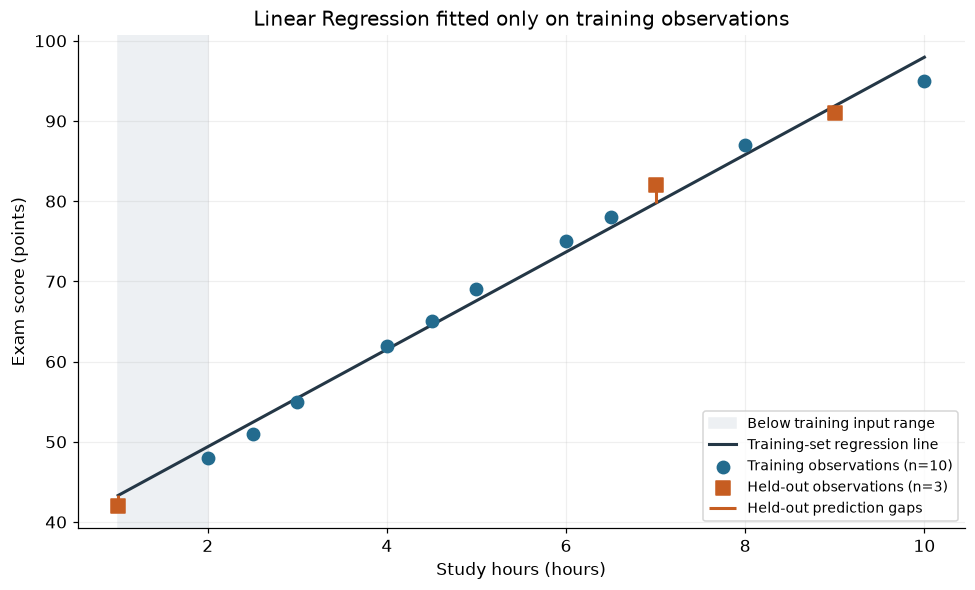

In [16]:
plot_student_scores(model)

The line summarizes the fitted relationship and provides estimates between observed study-hour values. The blue circles and orange squares distinguish training observations from held-out observations, while the vertical orange segments show test prediction gaps.

Most observations lie close to the line. The shaded strip marks inputs below the smallest training input; showing the complete dataset here does not mean that the test rows were used to fit the model.

## 6. Model Evaluation and Practical Prediction

### A and B. Evaluate the test predictions
MAE uses the actual test scores and their predictions to calculate the average absolute error. Taking absolute values prevents overestimates and underestimates from cancelling out.

In [17]:
mae = mean_absolute_error(y_test, predictions)
# A simple reference model predicts the training mean for every test student.
baseline_predictions = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
print(f"Linear Regression test MAE: {mae:.4f} exam-score points")
print(f"Training-mean baseline test MAE: {baseline_mae:.4f} exam-score points")
print(f"Students included in test evaluation: {len(y_test)}")
assert np.isclose(mae, test_results["AbsoluteError"].mean())
display(Markdown(
    f"Predictions differ from actual scores by **{mae:.2f} points on average in absolute terms** "
    f"on the {len(y_test)} held-out observations. The simple baseline has an MAE of "
    f"**{baseline_mae:.2f} points** on the same students, so study hours improve predictions "
    "for this particular split."
))

Linear Regression test MAE: 1.4823 exam-score points
Training-mean baseline test MAE: 20.8333 exam-score points
Students included in test evaluation: 3


Predictions differ from actual scores by **1.48 points on average in absolute terms** on the 3 held-out observations. The simple baseline has an MAE of **20.83 points** on the same students, so study hours improve predictions for this particular split.

MAE is measured in score points, not a percentage or a guarantee for every prediction. The baseline uses only the training mean, so it does not use held-out scores to produce its predictions. With only three test students, both results are sensitive to this particular split and are demonstrations rather than evidence of production reliability.

### Test errors shown individually
This chart complements MAE by showing which held-out students were overestimated or underestimated.

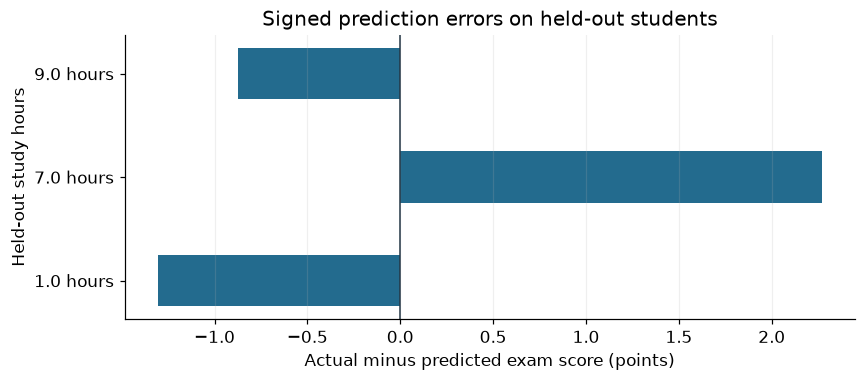

In [18]:
ordered_results = test_results.sort_values("StudyHours")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(ordered_results["StudyHours"].astype(str) + " hours", ordered_results["Error"],
        color="#236B8E", height=0.5)
ax.axvline(0, color="#243746", linewidth=1)
ax.set_xlabel("Actual minus predicted exam score (points)")
ax.set_ylabel("Held-out study hours")
ax.set_title("Signed prediction errors on held-out students")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

Negative bars mean the model overestimated the score; a positive bar means it underestimated the score. The largest absolute test error occurs at 7 study hours, and the average absolute size of these three errors is the MAE reported above.

### C. Predict the score for 7.5 hours
I give the model a DataFrame with the same feature name used during fitting.

In [19]:
practical_input = pd.DataFrame({"StudyHours": [7.5]})
predicted_score_7_5 = model.predict(practical_input)[0]
print(f"Predicted exam score for {practical_input.loc[0, 'StudyHours']:.1f} study hours: {predicted_score_7_5:.4f} points")
print(f"Observed study-hours range: {study_hours.min():.1f} to {study_hours.max():.1f} hours")

Predicted exam score for 7.5 study hours: 82.7675 points
Observed study-hours range: 1.0 to 10.0 hours


The estimate for 7.5 hours is interpolation because that input lies inside both the training range (2–10 hours) and the full observed range (1–10 hours). Being inside the range does not make an individual student's outcome certain; this prototype does not calculate a prediction interval.

### D. Test an extreme input
The next calculation deliberately asks for an estimate far outside the observed hours. Its purpose is to show why a numerical answer still needs to be checked against the context.

In [20]:
extreme_input = pd.DataFrame({"StudyHours": [100.0]})
predicted_score_100 = model.predict(extreme_input)[0]
print(f"Untrusted prediction for {extreme_input.loc[0, 'StudyHours']:.0f} study hours: {predicted_score_100:.4f} points")

Untrusted prediction for 100 study hours: 644.3603 points


The 100-hour input is far beyond the observed 1–10-hour range and the model returns a score far above any observed score. This is extreme extrapolation, so I would not trust the estimate. The model extends its straight line without accounting for score limits or changes in the relationship.

The score would be impossible **if** the exam were marked out of 100, but the assignment does not establish that marking scale. The 100-hour case is deliberately unrealistic for this prototype; because the study-time period is unspecified, the strongest reason to reject the estimate is that it lies far outside the supporting data.

## 7. Final Project Conclusion and Technical Quality

### A. Final project conclusion
The conclusion below draws its numerical results from the calculations above.

In [21]:
conclusion = f"""The supplied {len(df)} observations show a strong positive association between study hours and exam scores. The exploratory scatter plot follows a nearly straight upward pattern with no obvious isolated outliers. This supports trying Linear Regression, but it does not prove that studying longer alone causes higher scores.

The model was fitted only to {len(X_train)} training observations. Its regression line closely follows the plotted pattern, and its MAE on {len(X_test)} held-out observations is {mae:.2f} exam-score points. Predictions therefore differ from actual scores by that amount on average in absolute terms for this test set. The training-mean baseline has a larger MAE of {baseline_mae:.2f} points, providing a useful comparison on the same observations.

For 7.5 study hours, the model estimates {predicted_score_7_5:.2f} points. This demonstrates interpolation within both the training and full-data ranges, although it is not a guaranteed result for an individual student. The 100-hour estimate is unsupported extrapolation and should not be trusted.

The main limitations are the very small dataset and test set, the use of only one input feature, and uncertain generalizability to other students or courses. A future version should collect a larger, representative sample with attendance, prior grades, assignment performance, sleep, and course difficulty. Cross-validation and uncertainty estimates would strengthen evaluation. I recommend using this prototype for learning and exploration before considering real academic-support decisions."""
display(Markdown(conclusion))
conclusion_word_count = len(conclusion.split())
print(f"Conclusion word count: {conclusion_word_count}")
assert 150 <= conclusion_word_count <= 250

The supplied 13 observations show a strong positive association between study hours and exam scores. The exploratory scatter plot follows a nearly straight upward pattern with no obvious isolated outliers. This supports trying Linear Regression, but it does not prove that studying longer alone causes higher scores.

The model was fitted only to 10 training observations. Its regression line closely follows the plotted pattern, and its MAE on 3 held-out observations is 1.48 exam-score points. Predictions therefore differ from actual scores by that amount on average in absolute terms for this test set. The training-mean baseline has a larger MAE of 20.83 points, providing a useful comparison on the same observations.

For 7.5 study hours, the model estimates 82.77 points. This demonstrates interpolation within both the training and full-data ranges, although it is not a guaranteed result for an individual student. The 100-hour estimate is unsupported extrapolation and should not be trusted.

The main limitations are the very small dataset and test set, the use of only one input feature, and uncertain generalizability to other students or courses. A future version should collect a larger, representative sample with attendance, prior grades, assignment performance, sleep, and course difficulty. Cross-validation and uncertainty estimates would strengthen evaluation. I recommend using this prototype for learning and exploration before considering real academic-support decisions.

Conclusion word count: 218


### B. Technical quality and submission checklist
- [x] Exact supplied dataset used throughout one continuous seven-stage project.
- [x] NumPy arrays, statistics, Boolean comparison, and explanations included.
- [x] Pandas inspection, AboveAverage column, inclusive filter, and statistical reconciliation included.
- [x] Exploratory scatter and fitted line have titles, units, and legends.
- [x] Model uses StudyHours only; the required split is reproducible and test rows are excluded from fitting.
- [x] Test predictions, MAE, 7.5-hour prediction, and extrapolation limitations are explained.
- [x] A 150–250 word conclusion connects results, limitations, and improvements.
- [x] All code cells were executed in order in a fresh kernel, with outputs and plots saved.

### C. Library understanding
- **NumPy:** Stores numerical arrays, computes statistics and Boolean comparisons, and creates the baseline predictions.
- **Pandas:** Provides labeled tables, inspection summaries, derived columns, filters, and aligned prediction results.
- **Matplotlib:** Draws the exploratory scatter, fitted regression overlay, and signed test-error chart.
- **scikit-learn:** Splits observations, fits Linear Regression, predicts scores, and calculates test MAE.

### D. Short study guide
- **`np.mean()` and the Boolean mask:** The mean is one number; comparing every score with it gives one True/False per student. Summing the mask counts above-average scores.
- **Population versus sample spread:** `ddof=0` divides by n; `ddof=1` divides by n−1. Pandas defaults to the latter.
- **`X` and `y`:** X is a two-dimensional table of available inputs; y contains the observed scores. AboveAverage is excluded because it reveals information about the target.
- **`fit()` and `predict()`:** Fit learns slope and intercept by minimizing squared training errors. Predict uses those learned parameters to return one score per input row.
- **Signed error versus MAE:** Actual minus predicted can be positive or negative; MAE averages the absolute sizes so signs cannot cancel.
- **Interpolation and extrapolation:** Predictions within the training input range have direct range support; those beyond it require extending the relationship without comparable training observations.

### E. Final reproducibility checks
The checks below verify key numerical relationships and report the execution environment. They do not establish that this tiny dataset represents a wider student population.

In [22]:
import sys
import sklearn
import matplotlib

assert len(df) == len(study_hours) == len(exam_scores) == 13
assert list(X.columns) == ["StudyHours"]
assert len(X_train) == 10 and len(X_test) == 3
assert set(X_train.index).isdisjoint(X_test.index)
assert np.array_equal(df["AboveAverage"].to_numpy(), above_mean_mask)
assert np.isclose(mae, np.mean(np.abs(y_test.to_numpy() - predictions)))
assert X_train["StudyHours"].min() <= 7.5 <= X_train["StudyHours"].max()
assert 150 <= conclusion_word_count <= 250
print("Project checks passed: data, reporting feature, split, evaluation, and conclusion length.")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | Pandas {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__} | scikit-learn {sklearn.__version__}")

Project checks passed: data, reporting feature, split, evaluation, and conclusion length.
Python 3.14.7 | NumPy 2.5.3 | Pandas 3.0.6
Matplotlib 3.11.2 | scikit-learn 1.9.1
